# Tópico 004 - Notebook 01 — Mapa coroplético

**DEC1217 - Visualização Científica (PPGMC/UESC)** - Capítulo 7 (Geoespacial) de Schwabish, *Better Data Visualizations*.

**Pergunta do notebook:** onde o PIB per capita é alto ou baixo na Bahia, e o que muda quando trocamos valor absoluto por taxa, escolhemos as classes com critério e usamos uma projeção de área igual?

**Dados:** PIB dos Municípios 2022 (IBGE/SIDRA, tabela 5938) e população do Censo 2022 (IBGE/SIDRA, tabela 4714), nos 417 municípios baianos; malha municipal 2025 (IBGE). Fonte, licença e data de acesso em `data/README.md`.

**Roteiro:** 1 Definição e anatomia - 2 Quando usar (e quando não) - 3 Como ler - 4 Do livro ao nosso dado - 5 Boas práticas, com redesenhos "antes → depois" - 6 Alternativas.

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

import utils

utils.estilo()
rng = np.random.default_rng(utils.SEED)

bahia = utils.carregar_bahia()
bahia_desenho = utils.para_desenho(bahia)
contorno = utils.contorno_bahia()

print(f"{len(bahia)} municípios | população {bahia['pop'].sum():,.0f} | PIB R$ {bahia['pib_mil'].sum()/1e6:,.1f} bilhões")
bahia[["NM_MUN", "pop", "area_km2", "pib_mil", "pib_pc"]].describe().round(0)

417 municípios | população 14,141,626 | PIB R$ 402.6 bilhões


,pop,area_km2,pib_mil,pib_pc
count,417.0,417.0,417.0,417.0
mean,33913.0,1354.0,965579.0,20459.0
std,125853.0,1961.0,4174874.0,39174.0
min,3434.0,32.0,42164.0,7633.0
25%,10862.0,401.0,131798.0,10923.0
50%,16354.0,766.0,215874.0,13362.0
75%,27390.0,1525.0,472126.0,17384.0
max,2417678.0,15634.0,68764218.0,654785.0


## 1 - Definição e anatomia

Um **mapa coroplético** pinta unidades geográficas com uma cor que codifica uma quantidade: quanto mais escuro o tom, maior o valor. É o mapa de dados mais familiar, e por isso o mais fácil de ler e o mais fácil de usar mal.

Anatomia do nosso exemplo:

| Elemento | No nosso mapa |
| --- | --- |
| **Unidade geográfica** | cada polígono é um município (417) |
| **Variável** | PIB per capita 2022, em R$ por habitante: uma razão, não um total |
| **Classes e rampa de cor** | cinco faixas; cor sequencial de um só matiz, do claro (pouco) ao escuro (muito) |
| **Legenda** | as faixas, com o número de municípios em cada uma |
| **Projeção** | Albers de área igual, para que área no mapa seja área no terreno |
| **Fonte** | IBGE, sempre no rodapé |

PIB per capita = PIB (mil R$ × 1.000) ÷ população do Censo 2022. A tabela do IBGE não traz o per capita pronto, então calculamos com o mesmo ano nos dois lados.

In [14]:
CORTES = [10_000, 15_000, 25_000, 50_000]
ROTULOS = ["abaixo de R$ 10 mil", "R$ 10 a 15 mil", "R$ 15 a 25 mil", "R$ 25 a 50 mil", "R$ 50 mil ou mais"]

def classificar(valores, cortes):
    return np.digitize(valores, cortes)

bahia["classe"] = classificar(bahia["pib_pc"], CORTES)
bahia_desenho["classe"] = bahia["classe"].values
cont = bahia["classe"].value_counts().sort_index()
n_ate15 = int(cont.iloc[:2].sum())
n_topo = int(cont.iloc[-1])
print(cont.to_string())

def pintar(ax, gdf, classes, rampa=utils.RAMPA, borda="white", lw=0.25):
    gdf.plot(ax=ax, color=[rampa[i] for i in classes], edgecolor=borda, linewidth=lw)
    utils.sem_eixos(ax)

classe
0     62
1    203
2    100
3     36
4     16


figura salva: figs/fig_004_01_anatomia.png


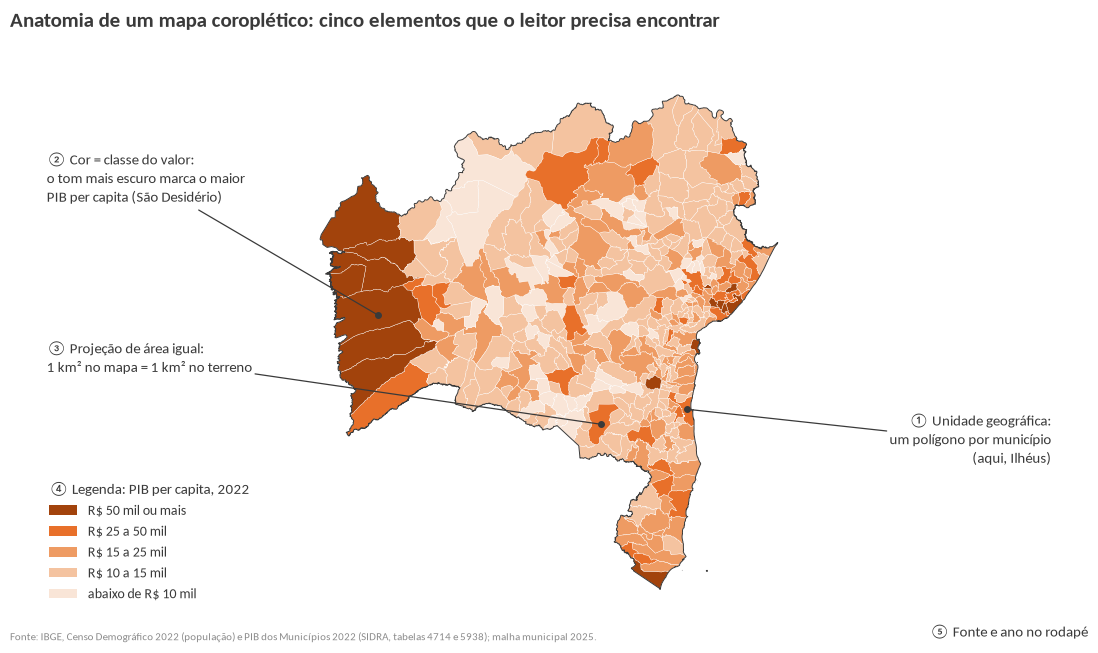

In [15]:
# Figura de anatomia: o mesmo mapa, com os elementos nomeados.
fig, ax = plt.subplots(figsize=(11, 6.4))
pintar(ax, bahia_desenho, bahia["classe"])
contorno.boundary.plot(ax=ax, color=utils.GRAFITE, linewidth=0.7)

def ponto(nome):
    return bahia.loc[bahia["NM_MUN"] == nome, "geometry"].representative_point().iloc[0]

minx, miny, maxx, maxy = bahia.total_bounds
ax.set_xlim(minx - 0.62 * (maxx - minx), maxx + 0.62 * (maxx - minx))

seta = dict(arrowstyle="-", color=utils.GRAFITE, lw=0.9, shrinkA=0, shrinkB=0)
def nota(texto, alvo, xy_texto, ha):
    p = ponto(alvo)
    ax.annotate(texto, xy=(p.x, p.y), xytext=xy_texto, textcoords="axes fraction", fontsize=11,
                ha=ha, va="center", color=utils.GRAFITE, arrowprops=seta)
    ax.plot(p.x, p.y, "o", ms=4, color=utils.GRAFITE)

nota("① Unidade geográfica:\num polígono por município\n(aqui, Ilhéus)", "Ilhéus", (0.99, 0.32), "right")
nota("② Cor = classe do valor:\no tom mais escuro marca o maior\nPIB per capita (São Desidério)", "São Desidério", (0.01, 0.80), "left")
nota("③ Projeção de área igual:\n1 km² no mapa = 1 km² no terreno", "Vitória da Conquista", (0.01, 0.47), "left")
ax.legend(handles=[Patch(facecolor=utils.RAMPA[i], label=ROTULOS[i]) for i in range(4, -1, -1)],
          title="④ Legenda: PIB per capita, 2022", title_fontsize=10.5, fontsize=10, frameon=False,
          loc="lower left", bbox_to_anchor=(0.0, 0.0), alignment="left")
fig.text(0.99, 0.015, "⑤ Fonte e ano no rodapé", ha="right", fontsize=10.5, color=utils.GRAFITE)
utils.cabecalho(fig, "Anatomia de um mapa coroplético: cinco elementos que o leitor precisa encontrar", None)
fig.subplots_adjust(top=0.90, bottom=0.05, left=0.01, right=0.99)
utils.fonte(fig)
utils.salvar(fig, "fig_004_01_anatomia.png")
plt.show()

## 2 - Quando usar (e quando não)

**Use** quando a pergunta é *onde?* e o padrão geográfico importa para o leitor, quando a variável é uma **taxa, razão ou densidade** (nunca um total que depende do tamanho da unidade) e quando o leitor se orienta pelo mapa familiar. Schwabish resume em duas perguntas: *quão importantes são os padrões geográficos?* e *quão importante é o leitor reconhecer o mapa?*

**Evite** quando:

- o valor exato importa mais que o padrão (a cor agrupa e esconde diferenças dentro da classe);
- as unidades são muito desiguais em área: o mapa dá peso visual à área, não às pessoas. O livro lembra que o maior PIB per capita do mundo, o de Luxemburgo, é difícil de achar no mapa por causa do tamanho do país;
- não há padrão geográfico claro, e uma dispersão ou um ranking mostram a mesma coisa com mais precisão.

Veja o efeito Luxemburgo na Bahia: onde estão os maiores PIB per capita?

figura salva: figs/fig_004_01_quando_nao_mapa.png


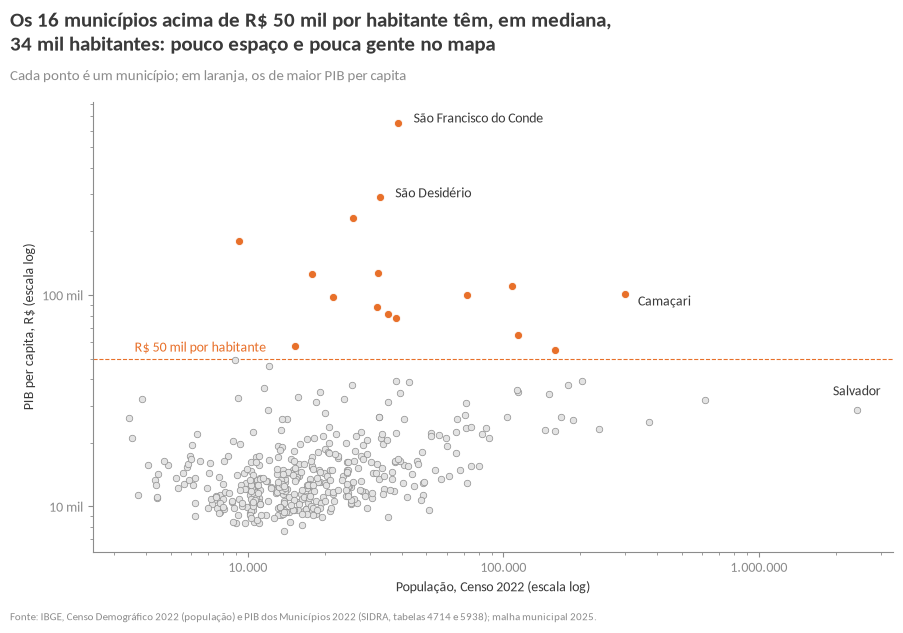

In [16]:
topo = bahia[bahia["classe"] == 4]
fig, ax = plt.subplots(figsize=(9.2, 6.2))
ax.scatter(bahia["pop"], bahia["pib_pc"], s=22, color=utils.CINZA_CLARO, edgecolor=utils.CINZA, linewidth=0.5, zorder=2)
ax.scatter(topo["pop"], topo["pib_pc"], s=34, color=utils.LARANJA, edgecolor="white", linewidth=0.6, zorder=3)
ax.set_xscale("log"); ax.set_yscale("log")
ax.axhline(50_000, color=utils.LARANJA, lw=0.8, ls="--", zorder=1)
ax.text(bahia["pop"].min() * 1.05, 52_000, "R$ 50 mil por habitante", color=utils.LARANJA, fontsize=10, va="bottom")
for nome, dx, dy, ha in [("São Francisco do Conde", 1.15, 1.0, "left"), ("São Desidério", 1.15, 1.0, "left"),
                         ("Salvador", 1.0, 1.18, "center"), ("Camaçari", 1.12, 0.88, "left")]:
    r = bahia[bahia["NM_MUN"] == nome].iloc[0]
    ax.text(r["pop"] * dx, r["pib_pc"] * dy, nome, fontsize=10, color=utils.GRAFITE, ha=ha)
ax.set_xlabel("População, Censo 2022 (escala log)"); ax.set_ylabel("PIB per capita, R$ (escala log)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:,.0f} mil".replace(",", "."))
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
med_pop_topo = topo["pop"].median()
utils.cabecalho(fig, f"Os {n_topo} municípios acima de R$ 50 mil por habitante têm, em mediana,\n{utils.br(med_pop_topo/1000)} mil habitantes: pouco espaço e pouca gente no mapa",
             "Cada ponto é um município; em laranja, os de maior PIB per capita", linhas=2)
fig.subplots_adjust(top=utils.topo(fig, 2), bottom=0.12, left=0.1, right=0.97)
utils.fonte(fig)
utils.salvar(fig, "fig_004_01_quando_nao_mapa.png")
plt.show()

## 3 - Como ler (passo a passo)

1. **Título e subtítulo**: o título diz a conclusão, o subtítulo diz o que a cor mede e em que ano.
2. **Legenda com barras**: cada faixa mostra quantos municípios caem nela. As duas faixas mais claras reúnem a maioria.
3. **Tom mais escuro**: onde estão os municípios de maior PIB per capita? Procure se formam grupos.
4. **Tom mais claro**: é a "cor padrão" da Bahia; a maior parte do mapa é clara.
5. **Cuidado com a área**: um polígono grande não significa muita gente nem muita riqueza total. O mapa mostra *razão*, não *volume*.
6. **Rodapé**: fonte e ano.

figura salva: figs/fig_004_01_depois.png


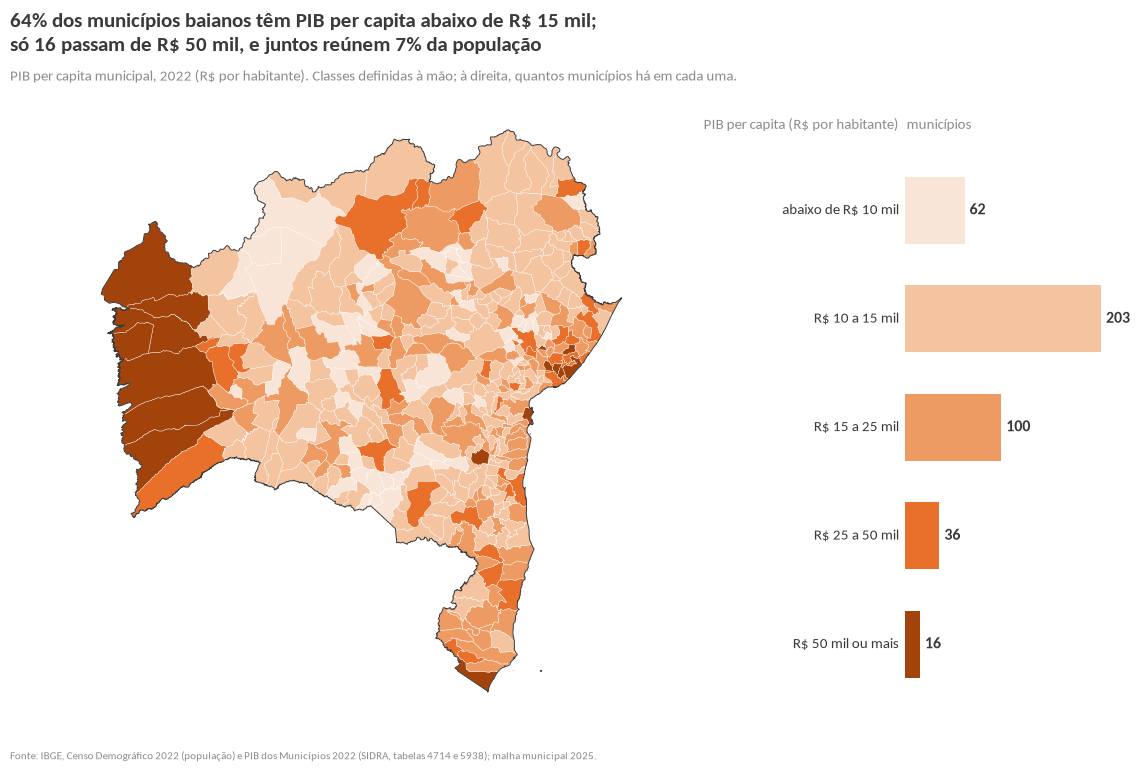

In [17]:
# O mapa final: taxa, classes escolhidas, rampa sequencial, projeção de área igual e legenda com a distribuição.
pop_topo = bahia.loc[bahia["classe"] == 4, "pop"].sum() / bahia["pop"].sum() * 100
fig = plt.figure(figsize=(11.5, 7.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.75, 1], left=0.01, right=0.99, top=utils.topo(fig, 2), bottom=0.06, wspace=0.04)
ax, axb = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
pintar(ax, bahia_desenho, bahia["classe"])
contorno.boundary.plot(ax=ax, color=utils.GRAFITE, linewidth=0.7)

# a legenda também mostra a distribuição: barras com o número de municípios por classe
y = np.arange(5)[::-1]
axb.barh(y, cont.values, color=utils.RAMPA, height=0.62)
for yi, n, rot in zip(y, cont.values, ROTULOS):
    axb.text(-6, yi, rot, ha="right", va="center", fontsize=11)
    axb.text(n + 5, yi, f"{n}", ha="left", va="center", fontsize=11.5, fontweight="bold")
axb.set_xlim(-175, 240); axb.set_ylim(-0.7, 5.0)
axb.text(-6, 4.75, "PIB per capita (R$ por habitante)", ha="right", fontsize=10.5, color=utils.CINZA)
axb.text(2, 4.75, "municípios", ha="left", fontsize=10.5, color=utils.CINZA)
axb.axis("off")

utils.cabecalho(fig, f"{n_ate15/len(bahia)*100:.0f}% dos municípios baianos têm PIB per capita abaixo de R$ 15 mil;\nsó {n_topo} passam de R$ 50 mil, e juntos reúnem {pop_topo:.0f}% da população",
             "PIB per capita municipal, 2022 (R$ por habitante). Classes definidas à mão; à direita, quantos municípios há em cada uma.", linhas=2)
utils.fonte(fig)
utils.salvar(fig, "fig_004_01_depois.png")
plt.show()

## 4 - Do livro ao nosso dado

O exemplo do livro é um coroplético do **PIB per capita no mundo (2017)**: razão em vez de total, rampa sequencial do claro ao escuro e o aviso de que países pequenos de renda alta quase somem no mapa. O nosso exemplo troca países por **municípios da Bahia** e 2017 por 2022, e mantém as mesmas decisões:

| Livro (mundo, 2017) | Nosso dado (Bahia, 2022) |
| --- | --- |
| Unidade: países | Unidade: 417 municípios |
| Variável: PIB per capita | Variável: PIB per capita (PIB 2022 ÷ população do Censo 2022) |
| Rampa sequencial, claro para escuro | Rampa sequencial de um só matiz, laranja da disciplina |
| Luxemburgo: o maior valor, num país minúsculo | São Francisco do Conde: o maior valor, num município pequeno |

A tabela abaixo mostra por que o "efeito Luxemburgo" existe aqui: os maiores PIB per capita aparecem em municípios com pouca gente.

In [18]:
t = bahia.sort_values("pib_pc", ascending=False).head(6).copy()
t["PIB per capita (R$)"] = t["pib_pc"].round(0).astype(int)
t["População"] = t["pop"].astype(int)
t["Área (km²)"] = t["area_km2"].round(0).astype(int)
t["Posição por população (de 417)"] = bahia["pop"].rank(ascending=False).loc[t.index].astype(int)
t[["NM_MUN", "PIB per capita (R$)", "População", "Área (km²)", "Posição por população (de 417)"]].rename(columns={"NM_MUN": "Município"}).reset_index(drop=True)

,Município,PIB per capita (R$),População,Área (km²),Posição por população (de 417)
0,São Francisco do Conde,654785,38733,270,60
1,São Desidério,289842,32828,15157,82
2,Formosa do Rio Preto,231187,25899,15634,112
3,Jaborandi,179534,9275,9955,354
4,Correntina,126642,32457,11504,86
5,Cairu,125466,17761,449,188


## 5 - Boas práticas (com redesenhos "antes → depois")

Quatro decisões separam um mapa que informa de um que engana: **o que** mapear (taxa, não total), **como** agrupar (as classes), **com que cor** (sequencial) e **sobre qual projeção**. O mapa "antes" abaixo junta os quatro erros; as figuras seguintes corrigem um de cada vez.

figura salva: figs/fig_004_01_antes.png


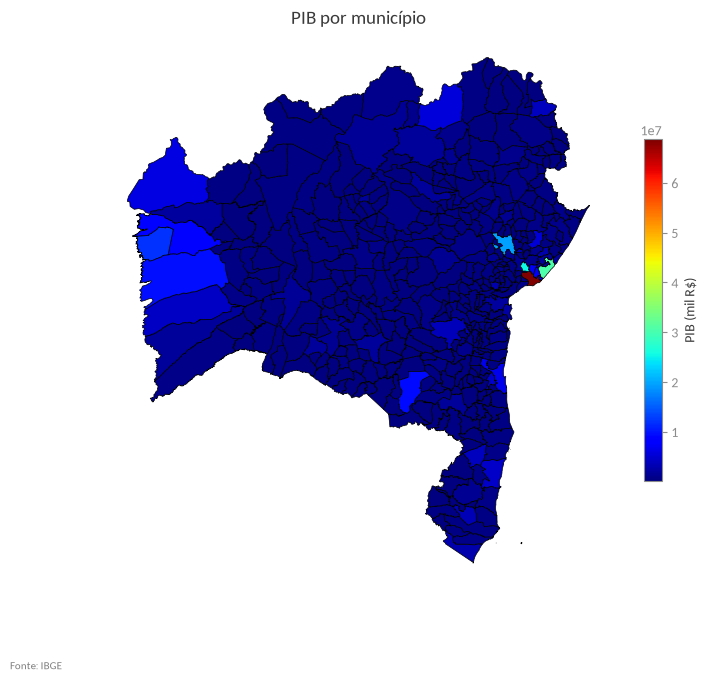

In [19]:
# ANTES: valor absoluto, escala contínua arco-íris, bordas pesadas, projeção Web Mercator, título genérico.
mer = bahia_desenho.to_crs(3857)
fig, ax = plt.subplots(figsize=(8.2, 7.4))
mer.plot(ax=ax, column="pib_mil", cmap="jet", edgecolor="black", linewidth=0.5, legend=True,
         legend_kwds={"shrink": 0.6, "label": "PIB (mil R$)"})
ax.set_axis_off(); ax.set_aspect("equal")
ax.set_title("PIB por município", fontsize=14)
fig.text(0.01, 0.01, "Fonte: IBGE", fontsize=8, color="gray")
utils.salvar(fig, "fig_004_01_antes.png")
plt.show()

### 5.1 - Mapeie uma taxa, não um total

Um total depende do tamanho da unidade: municípios populosos têm PIB total alto só por terem mais gente. À esquerda, o PIB total; à direita, o PIB per capita, com **as mesmas classes por quintis** para que a diferença venha da variável e não do agrupamento.

figura salva: figs/fig_004_01_a_total_vs_per_capita.png


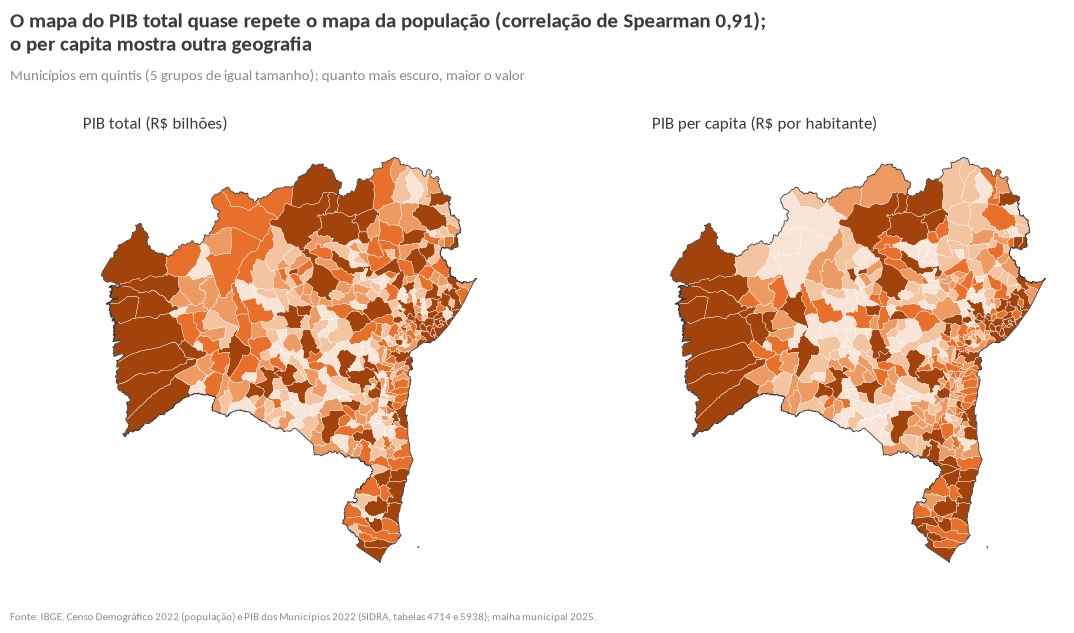

In [20]:
def quintis(v):
    cortes = np.quantile(v, [0.2, 0.4, 0.6, 0.8])
    return np.digitize(v, cortes)

rho = bahia[["pib_mil", "pop"]].corr(method="spearman").iloc[0, 1]
fig, axs = plt.subplots(1, 2, figsize=(11.5, 6.2))
for ax, col, titulo in zip(axs, ["pib_mil", "pib_pc"], ["PIB total (R$ bilhões)", "PIB per capita (R$ por habitante)"]):
    pintar(ax, bahia_desenho, quintis(bahia[col]))
    contorno.boundary.plot(ax=ax, color=utils.GRAFITE, linewidth=0.6)
    ax.set_title(titulo, fontsize=12, color=utils.GRAFITE, loc="left")
fig.subplots_adjust(top=utils.topo(fig, 2, extra=0.35), bottom=0.07, left=0.01, right=0.99, wspace=0.02)
utils.cabecalho(fig, f"O mapa do PIB total quase repete o mapa da população (correlação de Spearman {utils.br(rho, 2)});\no per capita mostra outra geografia",
             "Municípios em quintis (5 grupos de igual tamanho); quanto mais escuro, maior o valor", linhas=2)
utils.fonte(fig)
utils.salvar(fig, "fig_004_01_a_total_vs_per_capita.png")
plt.show()

### 5.2 - Escolha as classes e mostre a distribuição

O livro descreve quatro jeitos de agrupar: **sem classes** (rampa contínua), **intervalos iguais**, **quantis** (mesmo número de unidades por classe) e **cortes escolhidos** (números redondos ou naturais). Nenhum é certo ou errado; cada um conta uma história. Aqui a distribuição é muito assimétrica (um valor de R$ 655 mil contra uma mediana perto de R$ 13 mil), o que castiga os métodos automáticos.

figura salva: figs/fig_004_01_b_classes.png


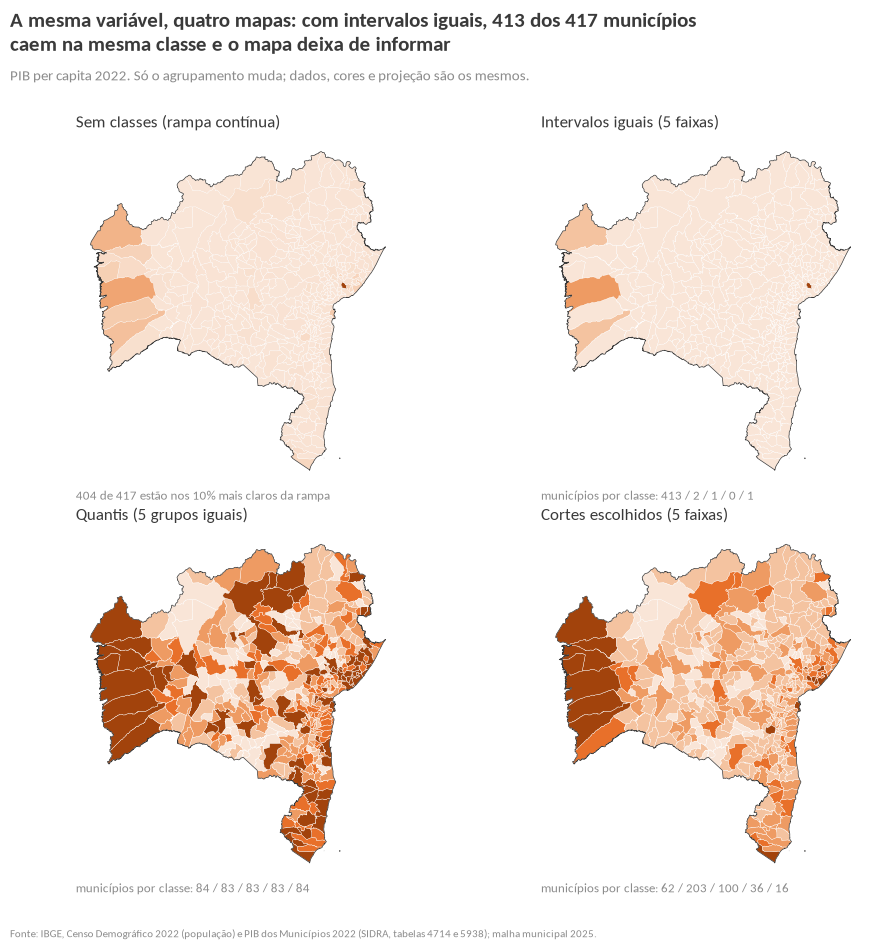

In [21]:
v = bahia["pib_pc"]
ei = np.linspace(v.min(), v.max(), 6)
variantes = [
    ("Sem classes (rampa contínua)", None),
    ("Intervalos iguais (5 faixas)", np.digitize(v, ei[1:-1])),
    ("Quantis (5 grupos iguais)", quintis(v)),
    ("Cortes escolhidos (5 faixas)", bahia["classe"].values),
]
cmap_cont = LinearSegmentedColormap.from_list("laranja", utils.RAMPA)

fig, axs = plt.subplots(2, 2, figsize=(9.4, 9.4))
for ax, (titulo, cls) in zip(axs.ravel(), variantes):
    if cls is None:
        bahia_desenho.plot(ax=ax, column="pib_pc", cmap=cmap_cont, edgecolor="white", linewidth=0.2)
        extra = f"{int((v < v.min() + 0.1 * (v.max() - v.min())).sum())} de 417 estão nos 10% mais claros da rampa"
        utils.sem_eixos(ax)
    else:
        pintar(ax, bahia_desenho, cls)
        n = np.bincount(cls, minlength=5)
        extra = "municípios por classe: " + " / ".join(str(k) for k in n)
    contorno.boundary.plot(ax=ax, color=utils.GRAFITE, linewidth=0.5)
    ax.set_title(titulo, fontsize=12, loc="left", color=utils.GRAFITE)
    ax.text(0.0, -0.01, extra, transform=ax.transAxes, fontsize=9.5, color=utils.CINZA, va="top")

n_ei = np.bincount(np.digitize(v, ei[1:-1]), minlength=5)[0]
utils.cabecalho(fig, f"A mesma variável, quatro mapas: com intervalos iguais, {n_ei} dos 417 municípios\ncaem na mesma classe e o mapa deixa de informar",
             "PIB per capita 2022. Só o agrupamento muda; dados, cores e projeção são os mesmos.", linhas=2)
fig.subplots_adjust(top=utils.topo(fig, 2, extra=0.35), bottom=0.07, left=0.01, right=0.99, hspace=0.12, wspace=0.02)
utils.fonte(fig)
utils.salvar(fig, "fig_004_01_b_classes.png")
plt.show()

**Decisão adotada:** cortes em R$ 10, 15, 25 e 50 mil. Eles separam o grosso dos municípios (R$ 10 a 15 mil) dos de renda intermediária e isolam o topo, e cada faixa tem pelo menos 16 municípios. O custo é que os cortes são escolhidos por nós: por isso a legenda do mapa final mostra a contagem, para o leitor ver o efeito da escolha.

### 5.3 - Use uma paleta sequencial

Quantidade pede cor que **cresce** do claro ao escuro. O arco-íris não tem ordem natural, e uma paleta divergente cria um ponto de virada que só faz sentido se o dado tiver um valor central (acima/abaixo de uma meta, por exemplo). O livro diz o mesmo: sem um ponto médio a comparar, a divergente é má escolha.

figura salva: figs/fig_004_01_c_paleta.png


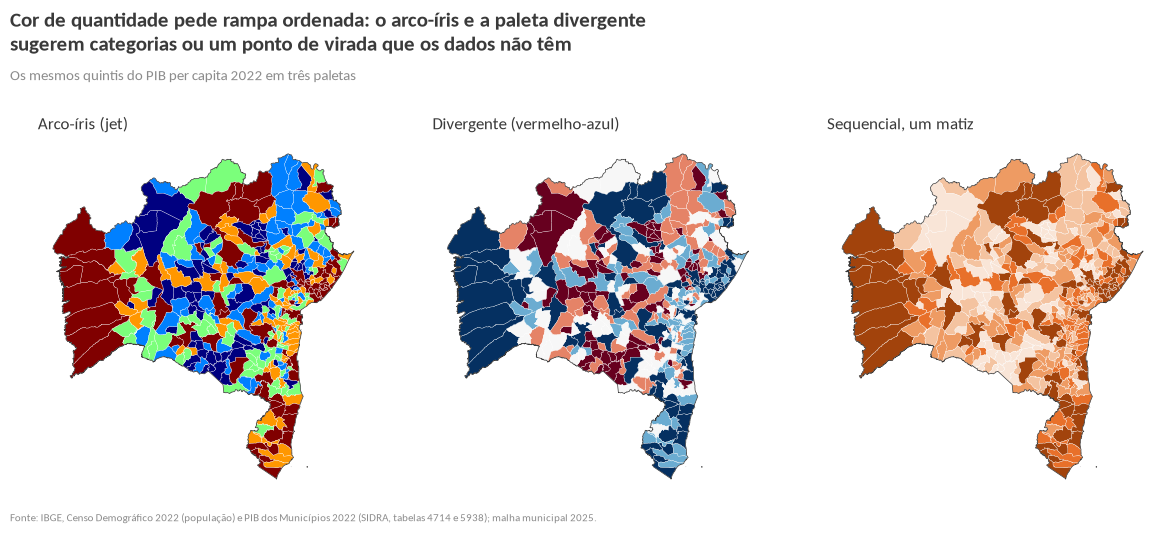

In [22]:
q = quintis(bahia["pib_pc"])
paletas = [
    ("Arco-íris (jet)", plt.get_cmap("jet", 5)),
    ("Divergente (vermelho-azul)", plt.get_cmap("RdBu", 5)),
    ("Sequencial, um matiz", LinearSegmentedColormap.from_list("seq", utils.RAMPA, N=5)),
]
fig, axs = plt.subplots(1, 3, figsize=(12, 5.2))
for ax, (titulo, cm) in zip(axs, paletas):
    bahia_desenho.plot(ax=ax, color=[cm(i) for i in q], edgecolor="white", linewidth=0.2)
    contorno.boundary.plot(ax=ax, color=utils.GRAFITE, linewidth=0.5)
    utils.sem_eixos(ax)
    ax.set_title(titulo, fontsize=12, loc="left", color=utils.GRAFITE)
fig.subplots_adjust(top=utils.topo(fig, 2, extra=0.35), bottom=0.06, left=0.01, right=0.99, wspace=0.02)
utils.cabecalho(fig, "Cor de quantidade pede rampa ordenada: o arco-íris e a paleta divergente\nsugerem categorias ou um ponto de virada que os dados não têm",
             "Os mesmos quintis do PIB per capita 2022 em três paletas", linhas=2)
utils.fonte(fig)
utils.salvar(fig, "fig_004_01_c_paleta.png")
plt.show()

### 5.4 - Escolha a projeção

O globo é redondo e o mapa é plano: toda projeção distorce alguma coisa. A **Web Mercator** (padrão de mapas na web) infla áreas longe do equador; para um coroplético, em que a área do polígono carrega o peso visual, a escolha mais segura é uma projeção de **área igual**, como a Albers que o livro apresenta. Na Bahia a distorção é pequena porque o contorno fica perto do equador, mas é mensurável.

figura salva: figs/fig_004_01_d_projecao.png


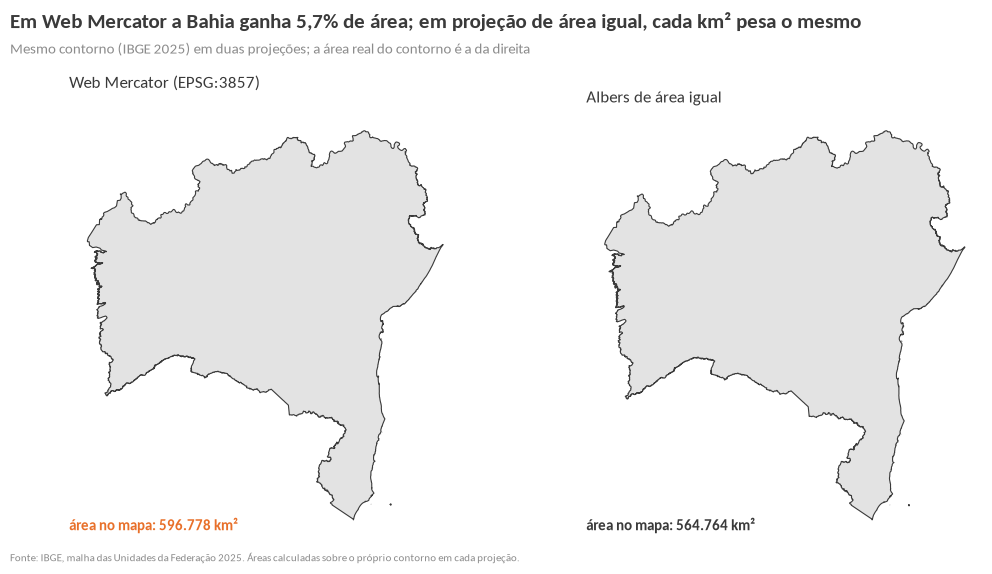

In [23]:
ba_ufs = contorno.to_crs(4674)                        # contorno em coordenadas geográficas (SIRGAS 2000)
mercator = ba_ufs.to_crs(3857)
albers = ba_ufs.to_crs(utils.CRS_AREA_IGUAL)
area_albers = albers.area.sum() / 1e6               # km² em área igual (referência correta)
area_mercator = mercator.area.sum() / 1e6           # km² "medidos" no mapa Mercator
infl = (area_mercator / area_albers - 1) * 100

fig, axs = plt.subplots(1, 2, figsize=(10.5, 5.6))
for ax, g, titulo, a in [(axs[0], mercator, "Web Mercator (EPSG:3857)", area_mercator), (axs[1], albers, "Albers de área igual", area_albers)]:
    g.plot(ax=ax, facecolor=utils.CINZA_CLARO, edgecolor=utils.GRAFITE, linewidth=0.8)
    utils.sem_eixos(ax)
    ax.set_title(titulo, fontsize=12, loc="left", color=utils.GRAFITE)
    ax.text(0.0, 0.02, f"área no mapa: {utils.br(a)} km²", transform=ax.transAxes, fontsize=11,
            color=utils.LARANJA if a == area_mercator else utils.GRAFITE, fontweight="bold")
fig.subplots_adjust(top=utils.topo(fig, 1, extra=0.35), bottom=0.05, left=0.01, right=0.99, wspace=0.02)
utils.cabecalho(fig, f"Em Web Mercator a Bahia ganha {utils.br(infl, 1)}% de área; em projeção de área igual, cada km² pesa o mesmo",
             "Mesmo contorno (IBGE 2025) em duas projeções; a área real do contorno é a da direita", linhas=1)
utils.fonte(fig, "Fonte: IBGE, malha das Unidades da Federação 2025. Áreas calculadas sobre o próprio contorno em cada projeção.")
utils.salvar(fig, "fig_004_01_d_projecao.png")
plt.show()

### 5.5 - O redesenho completo

O par `fig_004_01_antes.png` e `fig_004_01_depois.png` (gerados acima) resume o bloco: do valor absoluto, arco-íris, bordas pesadas e Mercator, para **taxa, classes escolhidas, rampa sequencial, área igual, título que diz a conclusão e legenda que mostra a distribuição**.

## 6 - Alternativas

Se a pergunta é *quem tem o maior PIB per capita?*, o mapa não é a melhor resposta (passo 2). Opções para a mesma pergunta, cada uma com seu custo:

| Alternativa | O que ganha | O que perde |
| --- | --- | --- |
| **Mapa cinza com destaque** (abaixo) | foca nos municípios que importam e reduz o ruído das classes | perde a gradação entre os demais |
| **Barras ordenadas / ranking** (abaixo) | valor exato e comparação direta | perde a localização |
| **Cartograma** (notebook 02) | devolve o peso à população | o mapa deixa de ser familiar |
| **Símbolos proporcionais** (notebook 03) | mostram totais sem depender da área | mais ocupação da tela e sobreposição |

A figura abaixo combina as duas primeiras: o mapa localiza, o ranking mede.

figura salva: figs/fig_004_01_e_alternativas.png


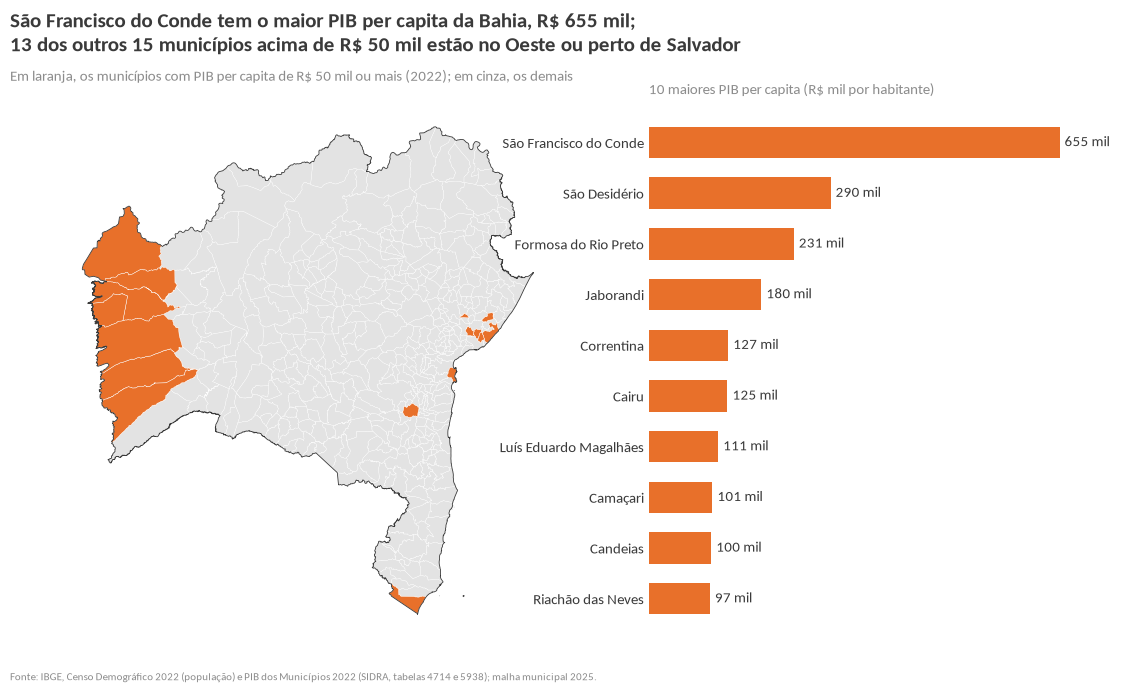

In [24]:
top = bahia.sort_values("pib_pc", ascending=False).head(10).iloc[::-1]
# onde ficam os 16 municípios do topo? (oeste = a oeste de 44°W; região de Salvador = caixa ao redor da capital)
pts = bahia[bahia["classe"] == 4].geometry.representative_point().to_crs(4674)
n_oeste = int((pts.x < -44).sum())
n_rms = int(((pts.x > -39.2) & (pts.x < -38.0) & (pts.y > -13.0) & (pts.y < -12.0)).sum())
fig = plt.figure(figsize=(11.5, 6.8))
gs = fig.add_gridspec(1, 2, width_ratios=[1.25, 1], left=0.01, right=0.98, top=utils.topo(fig, 2), bottom=0.07, wspace=0.08)
ax, axr = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

bahia_desenho.plot(ax=ax, color=utils.CINZA_CLARO, edgecolor="white", linewidth=0.25)
bahia_desenho[bahia["classe"] == 4].plot(ax=ax, color=utils.LARANJA, edgecolor="white", linewidth=0.3)
contorno.boundary.plot(ax=ax, color=utils.GRAFITE, linewidth=0.6)
utils.sem_eixos(ax)

axr.barh(top["NM_MUN"], top["pib_pc"] / 1000, color=utils.LARANJA, height=0.62)
for i, (nome, val) in enumerate(zip(top["NM_MUN"], top["pib_pc"] / 1000)):
    axr.text(val + 8, i, f"{utils.br(val)} mil", va="center", fontsize=10.5, color=utils.GRAFITE)
axr.set_xlim(0, 760); axr.set_xticks([]); axr.tick_params(axis="y", length=0, labelsize=10.5, colors=utils.GRAFITE)
for s in ("left", "bottom"): axr.spines[s].set_visible(False)
axr.set_title("10 maiores PIB per capita (R$ mil por habitante)", fontsize=11, loc="left", color=utils.CINZA)

utils.cabecalho(fig, f"São Francisco do Conde tem o maior PIB per capita da Bahia, R$ {utils.br(top['pib_pc'].iloc[-1]/1000)} mil;\n{n_oeste + n_rms} dos outros {n_topo - 1} municípios acima de R$ 50 mil estão no Oeste ou perto de Salvador",
             "Em laranja, os municípios com PIB per capita de R$ 50 mil ou mais (2022); em cinza, os demais", linhas=2)
utils.fonte(fig)
utils.salvar(fig, "fig_004_01_e_alternativas.png")
plt.show()

## O que levar deste notebook

- **Mapeie taxa, não total.** O total repete o mapa da população.
- **Escolha as classes olhando a distribuição** e mostre a contagem por classe na legenda.
- **Rampa sequencial** para quantidade; divergente só com ponto de virada real.
- **Projeção de área igual** para coroplético.
- **Pergunte antes se o mapa é a melhor forma**: às vezes um ranking responde melhor.